In [112]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import re

In [113]:
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from wordcloud import WordCloud
from collections import Counter
import random
import nltk
from nltk.corpus import stopwords

In [114]:
df_ba = pd.read_csv('BusinessAnalyst.csv')

In [115]:
df_ba.head()

,Unnamed: 0,index,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply
0,0,0,Business Analyst - Clinical & Logistics Platform,$56K-$102K (Glassdoor est.),Company Overview\n\n\nAt Memorial Sloan Ketter...,3.9,Memorial Sloan-Kettering\n3.9,"New York, NY","New York, NY",10000+ employees,1884,Nonprofit Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),"Mayo Clinic, The Johns Hopkins Hospital, MD An...",-1
1,1,1,Business Analyst,$56K-$102K (Glassdoor est.),We are seeking for an energetic and collaborat...,3.8,Paine Schwartz Partners\n3.8,"New York, NY","New York, NY",1 to 50 employees,-1,Company - Private,Venture Capital & Private Equity,Finance,Unknown / Non-Applicable,-1,True
2,2,2,Data Analyst,$56K-$102K (Glassdoor est.),"For more than a decade, Asembia has been worki...",3.6,Asembia\n3.6,"Florham Park, NJ","Florham Park, NJ",501 to 1000 employees,2004,Company - Private,Biotech & Pharmaceuticals,Biotech & Pharmaceuticals,$5 to $10 million (USD),-1,-1
3,3,3,"Information Security Analyst, Incident Response",$56K-$102K (Glassdoor est.),Job Description Summary\nThe Information Secur...,3.6,BD\n3.6,"Franklin Lakes, NJ","Franklin Lakes, NJ",10000+ employees,1897,Company - Public,Health Care Products Manufacturing,Manufacturing,$10+ billion (USD),"Abbott, Siemens, Baxter",-1
4,4,4,Analyst - FP&A Global Revenue,$56K-$102K (Glassdoor est.),Magnite is the world's largest independent sel...,3.4,Rubicon Project\n3.4,"New York, NY","Los Angeles, CA",201 to 500 employees,2007,Company - Public,Internet,Information Technology,$100 to $500 million (USD),"PubMatic, AppNexus, Index Exchange",True


In [116]:
df_da = pd.read_csv('DataAnalyst.csv')

In [117]:
df_da.head()

,Unnamed: 0,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply
0,0,"Data Analyst, Center on Immigration and Justic...",$37K-$66K (Glassdoor est.),Are you eager to roll up your sleeves and harn...,3.2,Vera Institute of Justice\n3.2,"New York, NY","New York, NY",201 to 500 employees,1961,Nonprofit Organization,Social Assistance,Non-Profit,$100 to $500 million (USD),-1,True
1,1,Quality Data Analyst,$37K-$66K (Glassdoor est.),Overview\n\nProvides analytical and technical ...,3.8,Visiting Nurse Service of New York\n3.8,"New York, NY","New York, NY",10000+ employees,1893,Nonprofit Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),-1,-1
2,2,"Senior Data Analyst, Insights & Analytics Team...",$37K-$66K (Glassdoor est.),We’re looking for a Senior Data Analyst who ha...,3.4,Squarespace\n3.4,"New York, NY","New York, NY",1001 to 5000 employees,2003,Company - Private,Internet,Information Technology,Unknown / Non-Applicable,GoDaddy,-1
3,3,Data Analyst,$37K-$66K (Glassdoor est.),Requisition NumberRR-0001939\nRemote:Yes\nWe c...,4.1,Celerity\n4.1,"New York, NY","McLean, VA",201 to 500 employees,2002,Subsidiary or Business Segment,IT Services,Information Technology,$50 to $100 million (USD),-1,-1
4,4,Reporting Data Analyst,$37K-$66K (Glassdoor est.),ABOUT FANDUEL GROUP\n\nFanDuel Group is a worl...,3.9,FanDuel\n3.9,"New York, NY","New York, NY",501 to 1000 employees,2009,Company - Private,Sports & Recreation,"Arts, Entertainment & Recreation",$100 to $500 million (USD),DraftKings,True


In [118]:
df_de = pd.read_csv('DataEngineer.csv')

In [119]:
df_de.head()

,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply
0,Data Engineer,$80K-$150K (Glassdoor est.),Company Description\nSagence is a management a...,4.5,Sagence\n4.5,"New York, NY","Chicago, IL",1 to 50 employees,2009,Company - Private,Consulting,Business Services,$10 to $25 million (USD),"WCI Consulting, PwC",-1
1,Senior Data Engineer (Healthcare Domain experi...,$80K-$150K (Glassdoor est.),"Key Responsibilities\n\n- Architect, build, an...",3.4,Enterprise Integration\n3.4,"New York, NY","Jacksonville, FL",51 to 200 employees,1998,Company - Private,IT Services,Information Technology,$25 to $50 million (USD),-1,-1
2,Data Engineers,$80K-$150K (Glassdoor est.),Overview\n\nJob description\n\nPosition Overvi...,5.0,Maestro Technologies\n5.0,"New York, NY","Trenton, NJ",51 to 200 employees,2003,Company - Private,IT Services,Information Technology,$5 to $10 million (USD),-1,-1
3,Client Trade Support Engineer,$80K-$150K (Glassdoor est.),About the Position\n\n\nThis position will sup...,4.8,Jane Street\n4.8,"New York, NY","New York, NY",501 to 1000 employees,2000,Company - Private,Investment Banking & Asset Management,Finance,Unknown / Non-Applicable,-1,-1
4,Data Engineer,$80K-$150K (Glassdoor est.),Data Engineer\n\nJob Details\nLevel\nExperienc...,3.7,GNY Insurance Companies\n3.7,"New York, NY","New York, NY",201 to 500 employees,1914,Company - Private,Insurance Carriers,Insurance,$100 to $500 million (USD),"Travelers, Chubb, Crum & Forster",True


In [120]:
df_ds = pd.read_csv('DataScientist.csv')

In [121]:
df_ds.head()

,Unnamed: 0,index,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply
0,0,0,Senior Data Scientist,$111K-$181K (Glassdoor est.),"ABOUT HOPPER\n\nAt Hopper, we’re on a mission ...",3.5,Hopper\n3.5,"New York, NY","Montreal, Canada",501 to 1000 employees,2007,Company - Private,Travel Agencies,Travel & Tourism,Unknown / Non-Applicable,-1,-1
1,1,1,"Data Scientist, Product Analytics",$111K-$181K (Glassdoor est.),"At Noom, we use scientifically proven methods ...",4.5,Noom US\n4.5,"New York, NY","New York, NY",1001 to 5000 employees,2008,Company - Private,"Health, Beauty, & Fitness",Consumer Services,Unknown / Non-Applicable,-1,-1
2,2,2,Data Science Manager,$111K-$181K (Glassdoor est.),Decode_M\n\nhttps://www.decode-m.com/\n\nData ...,-1.0,Decode_M,"New York, NY","New York, NY",1 to 50 employees,-1,Unknown,-1,-1,Unknown / Non-Applicable,-1,True
3,3,3,Data Analyst,$111K-$181K (Glassdoor est.),Sapphire Digital seeks a dynamic and driven mi...,3.4,Sapphire Digital\n3.4,"Lyndhurst, NJ","Lyndhurst, NJ",201 to 500 employees,2019,Company - Private,Internet,Information Technology,Unknown / Non-Applicable,"Zocdoc, Healthgrades",-1
4,4,4,"Director, Data Science",$111K-$181K (Glassdoor est.),"Director, Data Science - (200537)\nDescription...",3.4,United Entertainment Group\n3.4,"New York, NY","New York, NY",51 to 200 employees,2007,Company - Private,Advertising & Marketing,Business Services,Unknown / Non-Applicable,"BBDO, Grey Group, Droga5",-1


In [122]:
cols = [
    'Job Title', 'Salary Estimate', 'Job Description', 'Rating',
    'Company Name', 'Location', 'Headquarters', 'Size', 'Founded',
    'Type of ownership', 'Industry', 'Sector', 'Revenue',
    'Competitors', 'Easy Apply'
]

In [123]:
df_da = df_da[cols]
df_ds = df_ds[cols]
df_ba = df_ba[cols]
df_de = df_de[cols]

In [124]:
df_ba['Role'] = 'Business Analyst'
df_da['Role'] = 'Data Analyst'
df_de['Role'] = 'Data Engineer'
df_ds['Role'] = 'Data Scientist'

In [125]:
df = pd.concat([df_ba, df_da, df_de, df_ds], ignore_index=True)

In [126]:
df.head()

,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply,Role
0,Business Analyst - Clinical & Logistics Platform,$56K-$102K (Glassdoor est.),Company Overview\n\n\nAt Memorial Sloan Ketter...,3.9,Memorial Sloan-Kettering\n3.9,"New York, NY","New York, NY",10000+ employees,1884,Nonprofit Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),"Mayo Clinic, The Johns Hopkins Hospital, MD An...",-1,Business Analyst
1,Business Analyst,$56K-$102K (Glassdoor est.),We are seeking for an energetic and collaborat...,3.8,Paine Schwartz Partners\n3.8,"New York, NY","New York, NY",1 to 50 employees,-1,Company - Private,Venture Capital & Private Equity,Finance,Unknown / Non-Applicable,-1,True,Business Analyst
2,Data Analyst,$56K-$102K (Glassdoor est.),"For more than a decade, Asembia has been worki...",3.6,Asembia\n3.6,"Florham Park, NJ","Florham Park, NJ",501 to 1000 employees,2004,Company - Private,Biotech & Pharmaceuticals,Biotech & Pharmaceuticals,$5 to $10 million (USD),-1,-1,Business Analyst
3,"Information Security Analyst, Incident Response",$56K-$102K (Glassdoor est.),Job Description Summary\nThe Information Secur...,3.6,BD\n3.6,"Franklin Lakes, NJ","Franklin Lakes, NJ",10000+ employees,1897,Company - Public,Health Care Products Manufacturing,Manufacturing,$10+ billion (USD),"Abbott, Siemens, Baxter",-1,Business Analyst
4,Analyst - FP&A Global Revenue,$56K-$102K (Glassdoor est.),Magnite is the world's largest independent sel...,3.4,Rubicon Project\n3.4,"New York, NY","Los Angeles, CA",201 to 500 employees,2007,Company - Public,Internet,Information Technology,$100 to $500 million (USD),"PubMatic, AppNexus, Index Exchange",True,Business Analyst


In [127]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12782 entries, 0 to 12781
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Job Title          12782 non-null  object
 1   Salary Estimate    12782 non-null  object
 2   Job Description    12782 non-null  object
 3   Rating             12782 non-null  object
 4   Company Name       12781 non-null  object
 5   Location           12782 non-null  object
 6   Headquarters       12782 non-null  object
 7   Size               12782 non-null  object
 8   Founded            12782 non-null  object
 9   Type of ownership  12782 non-null  object
 10  Industry           12782 non-null  object
 11  Sector             12782 non-null  object
 12  Revenue            12782 non-null  object
 13  Competitors        12382 non-null  object
 14  Easy Apply         12382 non-null  object
 15  Role               12782 non-null  object
dtypes: object(16)
memory usage: 1.6+ MB


In [128]:
df.describe(include='all')

,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply,Role
count,12782,12782,12782,12782.0,12781,12782,12782,12782,12782,12782,12782,12782,12782,12382,12382,12782
unique,5979,464,10340,79.0,4947,411,1035,17,406,33,124,63,15,894,2,4
top,Data Analyst,$43K-$84K (Glassdoor est.),Citi\n3.7,-1.0,"Staffigo Technical Services, LLC\n5.0","New York, NY","New York, NY",10000+ employees,-1,Company - Private,IT Services,Information Technology,Unknown / Non-Applicable,-1,-1,Business Analyst
freq,801,84,22,915.0,242,1047,891,2642,2208,6679,1772,3644,3356,8917,11859,4092


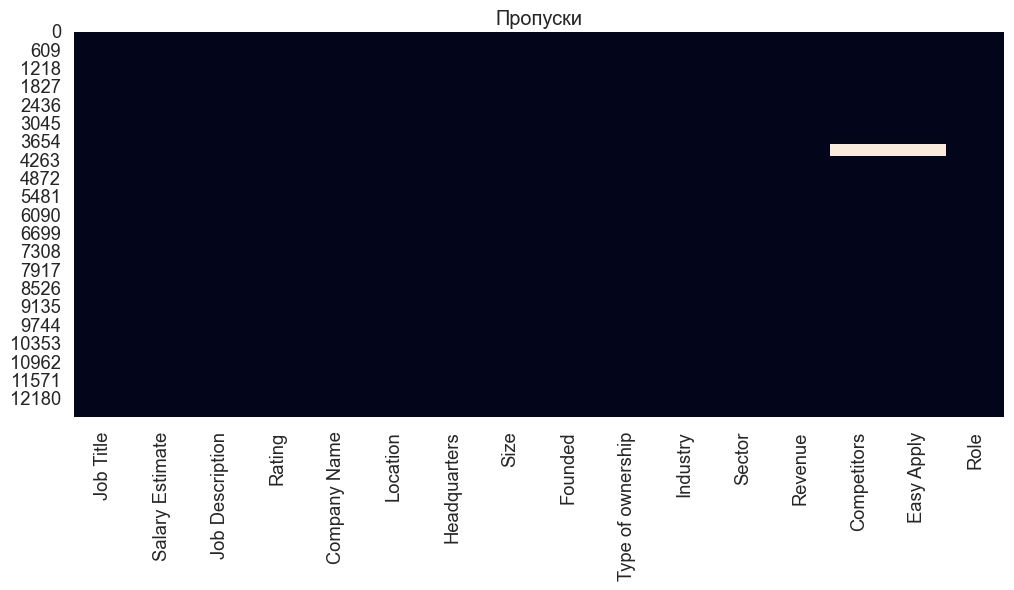

In [129]:
sns.set(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(12,5))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Пропуски")
plt.show()

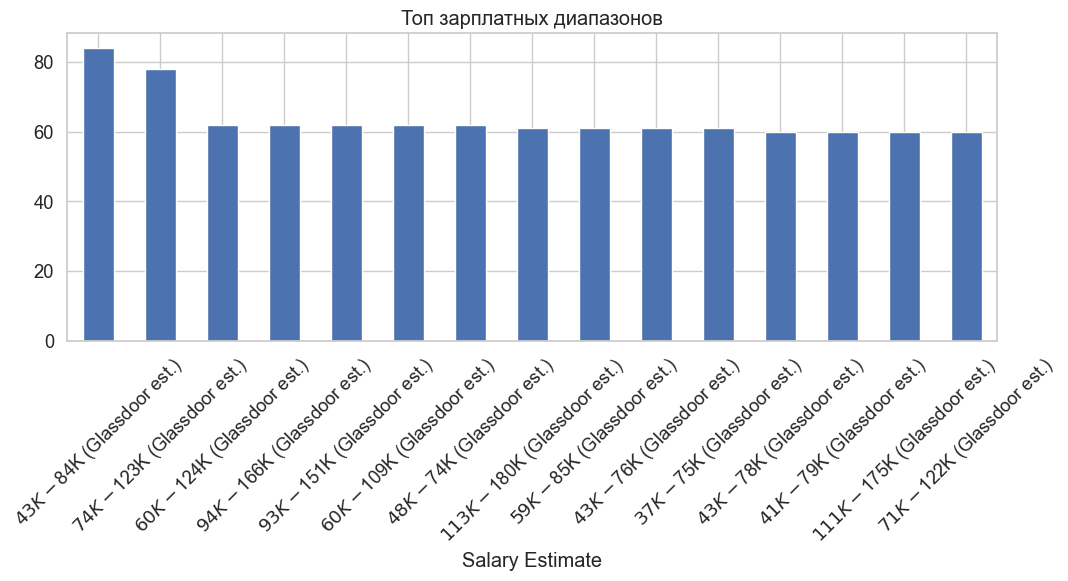

In [130]:
sns.set_theme(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(12,4))
df['Salary Estimate'].value_counts().head(15).plot(kind='bar')
plt.xticks(rotation=45)
plt.title("Топ зарплатных диапазонов")
plt.show()

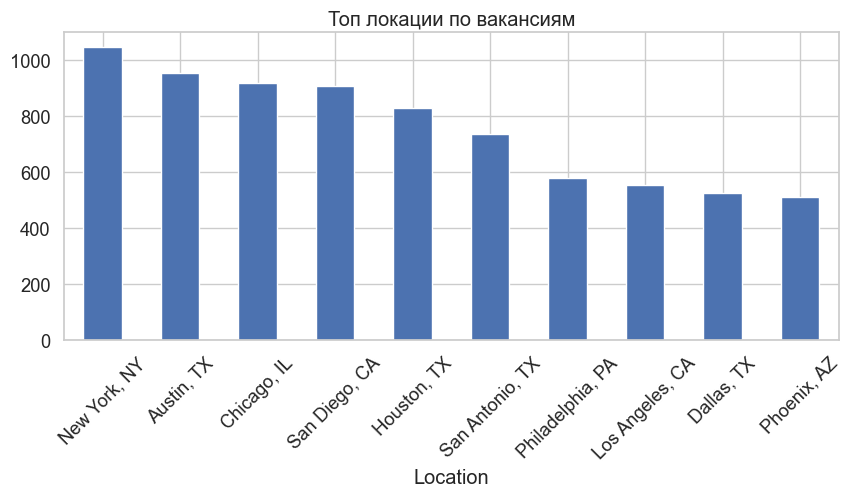

In [131]:
sns.set_theme(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(10,4))
df['Location'].value_counts().head(10).plot(kind='bar')
plt.xticks(rotation=45)
plt.title("Топ локации по вакансиям")
plt.show()

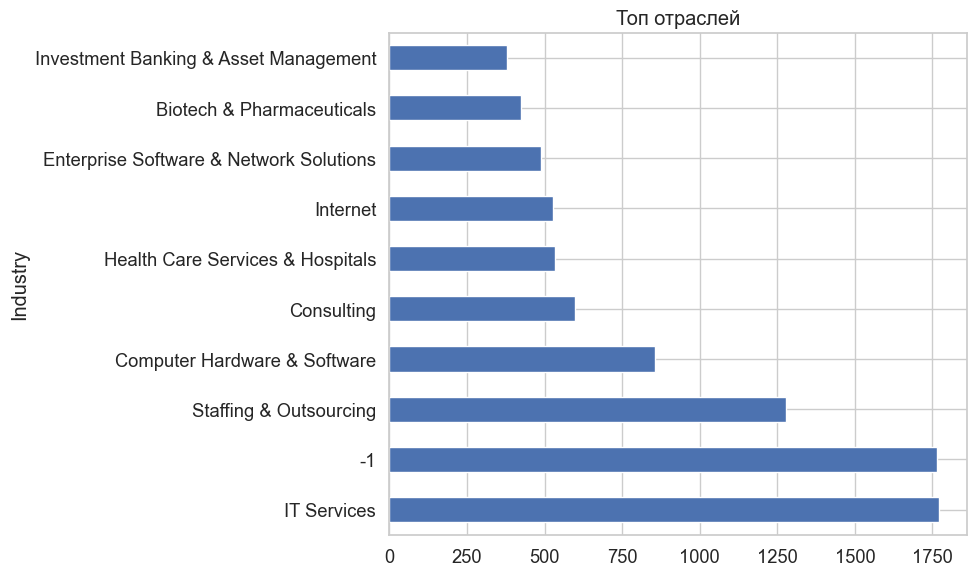

In [132]:
sns.set(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(10,6))
df['Industry'].value_counts().head(10).plot(kind='barh')
plt.title("Топ отраслей")
plt.tight_layout()
plt.show()


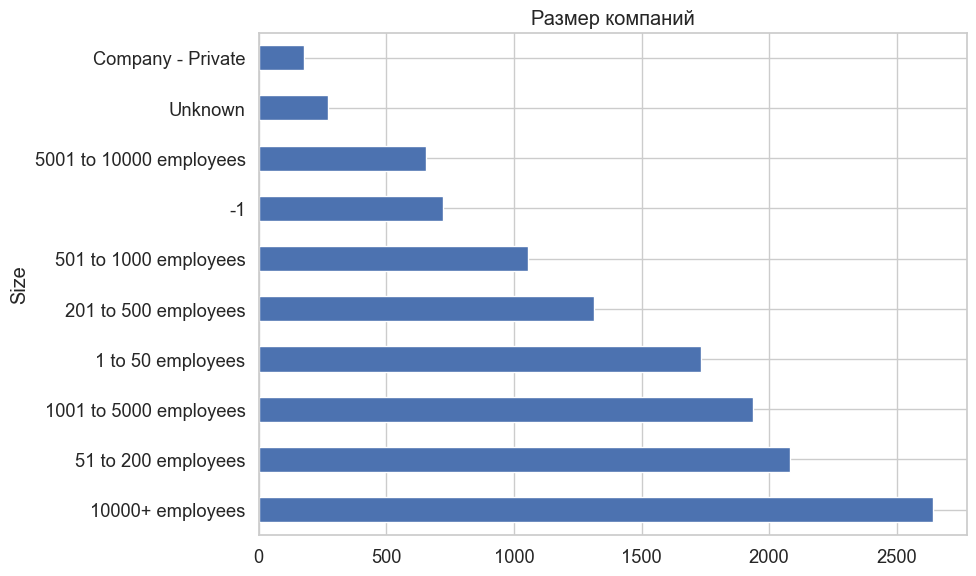

In [133]:
sns.set(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(10,6))
df['Size'].value_counts().head(10).plot(kind='barh')
plt.title("Размер компаний")
plt.tight_layout()
plt.show()

In [134]:
df['Revenue'].value_counts()

Revenue
Unknown / Non-Applicable            3356
$10+ billion (USD)                  1591
$100 to $500 million (USD)          1211
-1                                  1097
$50 to $100 million (USD)            917
$2 to $5 billion (USD)               711
$10 to $25 million (USD)             689
$25 to $50 million (USD)             563
$1 to $5 million (USD)               555
$1 to $2 billion (USD)               513
$5 to $10 billion (USD)              416
Less than $1 million (USD)           411
$500 million to $1 billion (USD)     392
$5 to $10 million (USD)              359
True                                   1
Name: count, dtype: int64

##Очистка колонок 

In [135]:
df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

упрощаем Job Title

In [136]:
df['job_title'] = df['job_title'].str.split(',').str[0]
df['job_title'] = df['job_title'].str.split('/').str[0]
df['job_title'] = df['job_title'].str.split('-').str[0]
df['job_title'] = df['job_title'].str.strip()

извлекаем среднюю зарплату

In [137]:
def extract_avg_salary(x):
    if pd.isna(x) or x == '-1':
        return np.nan
    # Примеры: $56K-$102K (Glassdoor est.), $43K-$84K ...
    nums = re.findall(r'\$?(\d+)K', str(x))
    if len(nums) == 2:
        return (int(nums[0]) + int(nums[1])) / 2
    elif len(nums) == 1:
        return int(nums[0])
    else:
        return np.nan

In [138]:
df['salary_avg_k'] = df['salary_estimate'].apply(extract_avg_salary)

рейтинг

In [139]:
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
df['rating'] = df['rating'].replace(-1.0, np.nan)

убираем рейтинг из названия

In [140]:
df['company_name'] = df['company_name'].astype(str)
df['company_name'] = df['company_name'].apply(lambda x: x.split('\n')[0] if '\n' in x else x)
df['company_name'] = df['company_name'].apply(lambda x: re.sub(r'\d\.\d$', '', x).strip())

Location и Headquarters - оставляем только город

In [141]:
df['location_city'] = df['location'].str.split(',').str[0].str.strip()
df['hq_city'] = df['headquarters'].str.split(',').str[0].str.strip()

Size переводим в среднее количество сотрудников

In [142]:
def clean_size(x):
    if pd.isna(x) or x in ['-1', 'Unknown']:
        return np.nan
    x = str(x)
    if 'to' in x:
        a, b = x.split('to')
        a = re.findall(r'\d+', a)[0]
        b = re.findall(r'\d+', b)[0]
        return (int(a) + int(b)) / 2
    elif '+' in x:
        return int(re.findall(r'\d+', x)[0]) + 500  # грубая оценка
    elif 'employees' in x:
        return int(re.findall(r'\d+', x)[0])
    else:
        return np.nan

In [143]:
df['size_avg'] = df['size'].apply(clean_size)

Возраст компании

In [144]:

df['founded'] = pd.to_numeric(df['founded'], errors='coerce')

Type of ownership

In [145]:
df['ownership'] = df['type_of_ownership'].astype(str)
df['ownership'] = df['ownership'].replace(['-1', 'Unknown'], np.nan)
df['ownership'] = df['ownership'].apply(lambda x: x.replace('Company - ', '') if pd.notna(x) else x)

Revenue — упрощаем до числового признака

In [146]:
def revenue_to_numeric(x):
    if pd.isna(x) or x in ['-1', 'Unknown / Non-Applicable']:
        return np.nan
    x = str(x)
    if 'billion' in x or '+ billion' in x:
        return 10
    elif 'million' in x and ('100 to 500' in x or '500 to 1' in x or '1 to 2' in x or '2 to 5' in x or '5 to 10' in x):
        return 5
    elif 'million' in x:
        return 2
    else:
        return 1

df['revenue_level'] = df['revenue'].apply(revenue_to_numeric)

Easy Apply

In [147]:
df['easy_apply'] = df['easy_apply'].replace(['-1', 'False'], False)
df['easy_apply'] = df['easy_apply'].replace(['True', 'TRUE'], True)
df['easy_apply'] = df['easy_apply'].fillna(False).astype(bool)

/var/folders/8_/ss2c3myd785fm4m9w3q294100000gn/T/ipykernel_18124/431346128.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['easy_apply'] = df['easy_apply'].fillna(False).astype(bool)


In [148]:
columns_to_keep = [
    'job_title',
    'salary_avg_k',
    'rating',
    'company_name',
    'location_city',
    'hq_city',
    'size_avg',
    'founded',
    'ownership',
    'sector',
    'revenue_level',
    'easy_apply'
]

In [149]:
df_clean = df[columns_to_keep].copy()

In [150]:
df_clean['founded'] = df_clean['founded'].replace(-1, np.nan)
df_clean['size_avg'] = df_clean['size_avg'].replace(-1, np.nan)  
df_clean['revenue_level'] = df_clean['revenue_level'].replace(-1, np.nan)
df_clean['ownership'] = df_clean['ownership'].replace('-1', np.nan)

In [151]:
string_cols = ['job_title', 'company_name', 'location_city', 'hq_city', 'ownership', 'sector']
for col in string_cols:
    df_clean[col] = df_clean[col].astype(str).str.lower()

In [152]:
df_clean.head()

,job_title,salary_avg_k,rating,company_name,location_city,hq_city,size_avg,founded,ownership,sector,revenue_level,easy_apply
0,business analyst,79.0,3.9,memorial sloan-kettering,new york,new york,10500.0,1884.0,nonprofit organization,health care,10.0,False
1,business analyst,79.0,3.8,paine schwartz partners,new york,new york,25.5,NaN,private,finance,NaN,True
2,data analyst,79.0,3.6,asembia,florham park,florham park,750.5,2004.0,private,biotech & pharmaceuticals,2.0,False
3,information security analyst,79.0,3.6,bd,franklin lakes,franklin lakes,10500.0,1897.0,public,manufacturing,10.0,False
4,analyst,79.0,3.4,rubicon project,new york,los angeles,350.5,2007.0,public,information technology,2.0,True


In [153]:
df_clean.describe()

,salary_avg_k,rating,size_avg,founded,revenue_level
count,12360.000000,11149.000000,11416.000000,9227.000000,8329.000000
mean,91.006634,3.776993,3505.530571,1977.233662,5.479769
std,34.693458,0.639663,4248.718446,47.853981,3.966400
min,33.500000,1.000000,25.500000,1625.000000,1.000000
25%,63.500000,3.400000,125.500000,1967.000000,2.000000
50%,83.000000,3.800000,750.500000,1997.000000,2.000000
75%,111.500000,4.100000,7500.500000,2006.000000,10.000000
max,225.000000,5.000000,10500.000000,2020.000000,10.000000


In [154]:
df_clean.describe(include="O")

,job_title,company_name,location_city,hq_city,ownership,sector
count,12782,12782,12782,12782,12782,12782
unique,4060,4824,401,981,32,63
top,data analyst,"staffigo technical services, llc",new york,new york,private,information technology
freq,1063,242,1047,906,6679,3644


In [155]:
df_clean.isna().sum()

job_title           0
salary_avg_k      422
rating           1633
company_name        0
location_city       0
hq_city             0
size_avg         1366
founded          3555
ownership           0
sector              0
revenue_level    4453
easy_apply          0
dtype: int64

In [156]:
df_clean['salary_avg_k'] = df_clean.groupby('job_title')['salary_avg_k'].transform(lambda x: x.fillna(x.median()))
df_clean['salary_avg_k'] = df_clean['salary_avg_k'].fillna(df_clean['salary_avg_k'].median())

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  

In [157]:
df_clean['rating'] = df_clean.groupby('sector')['rating'].transform(lambda x: x.fillna(x.median()))
df_clean['rating'] = df_clean['rating'].fillna(df_clean['rating'].median())

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  

In [158]:
df_clean['size_avg'] = df_clean.groupby('sector')['size_avg'].transform(lambda x: x.fillna(x.median()))
df_clean['size_avg'] = df_clean['size_avg'].fillna(df_clean['size_avg'].median())

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  

In [159]:
df_clean['revenue_level'] = df_clean.groupby('sector')['revenue_level'].transform(lambda x: x.fillna(x.median()))
df_clean['revenue_level'] = df_clean['revenue_level'].fillna(df_clean['revenue_level'].median())

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  

In [160]:
df_clean['ownership'] = df_clean['ownership'].fillna('unknown')

In [161]:
df_clean['company_age'] = 2025 - df_clean['founded']

In [162]:
df_clean['company_age'] = df_clean.groupby('sector')['company_age'].transform(lambda x: x.fillna(x.median()))
df_clean['company_age'] = df_clean['company_age'].fillna(df_clean['company_age'].median())
df_clean['founded'] = 2025 - df_clean['company_age']

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  

In [163]:
df_clean.isna().sum()

job_title        0
salary_avg_k     0
rating           0
company_name     0
location_city    0
hq_city          0
size_avg         0
founded          0
ownership        0
sector           0
revenue_level    0
easy_apply       0
company_age      0
dtype: int64

In [164]:
df_clean.head()

,job_title,salary_avg_k,rating,company_name,location_city,hq_city,size_avg,founded,ownership,sector,revenue_level,easy_apply,company_age
0,business analyst,79.0,3.9,memorial sloan-kettering,new york,new york,10500.0,1884.0,nonprofit organization,health care,10.0,False,141.0
1,business analyst,79.0,3.8,paine schwartz partners,new york,new york,25.5,1971.0,private,finance,10.0,True,54.0
2,data analyst,79.0,3.6,asembia,florham park,florham park,750.5,2004.0,private,biotech & pharmaceuticals,2.0,False,21.0
3,information security analyst,79.0,3.6,bd,franklin lakes,franklin lakes,10500.0,1897.0,public,manufacturing,10.0,False,128.0
4,analyst,79.0,3.4,rubicon project,new york,los angeles,350.5,2007.0,public,information technology,2.0,True,18.0
